# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1: scan dimensions and 16-bit storage (decimal MB)
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1_000_000

# TODO 2: physical extent (x, y, z) and voxel volume
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3: one ray per x-z pixel; each ray samples all y positions
samples_per_frame = 512 * 300 * 512
samples_video = samples_per_frame * 120

# TODO 4: early termination retains 35% of the full sample count
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 157.3 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** Ignoring anisotropic spacing would distort anatomy: the 1.0-mm direction would be displayed as if it had the same physical size as the 0.5-mm directions, making structures appear stretched or compressed in coronal and sagittal views. Measurements such as lesion dimensions and distances would also be wrong because pixel counts would be interpreted with an incorrect physical scale. The software must apply the voxel spacing (aspect ratio) when displaying slices.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

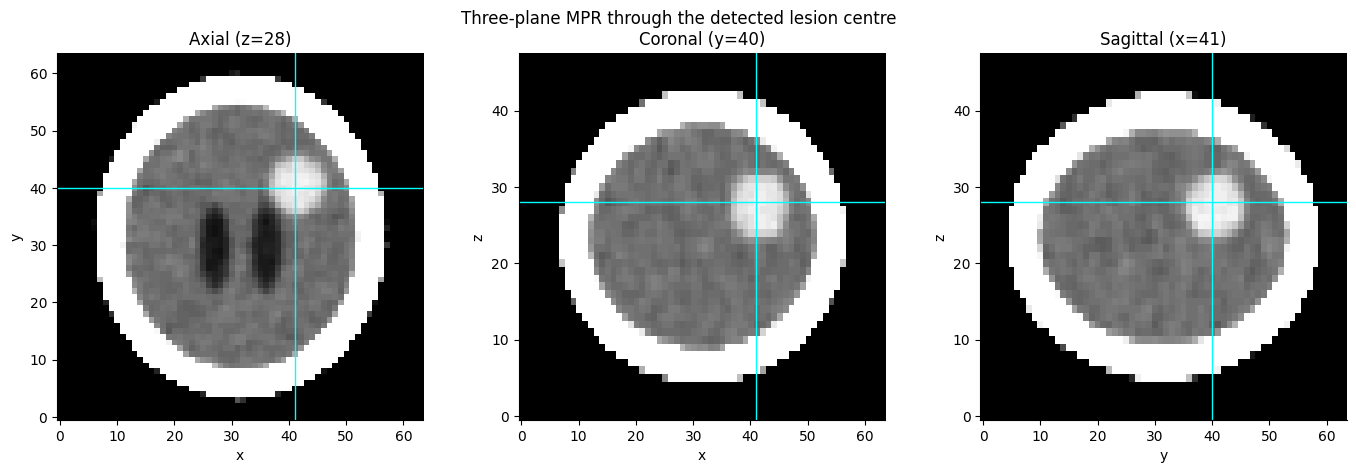

Detected centroid (z, y, x): (np.int64(28), np.int64(40), np.int64(41))
Centroid distance from evaluation-only truth: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: restrict the HU candidates to the eroded interior brain region
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: retain the largest connected component and find its integer centroid
components, n_components = ndimage.label(candidates)
component_sizes = np.bincount(components.ravel())
component_sizes[0] = 0
largest_id = component_sizes.argmax()
lesion = components == largest_id
cz, cy, cx = np.round(ndimage.center_of_mass(lesion)).astype(int)

# TODO 3: axial, coronal and sagittal MPR slices through the centroid
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap="gray", origin="lower", aspect="equal")
axes[0].axhline(cy, color="cyan", lw=1); axes[0].axvline(cx, color="cyan", lw=1)
axes[0].set_title(f"Axial (z={cz})"); axes[0].set_xlabel("x"); axes[0].set_ylabel("y")

axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="cyan", lw=1); axes[1].axvline(cx, color="cyan", lw=1)
axes[1].set_title(f"Coronal (y={cy})"); axes[1].set_xlabel("x"); axes[1].set_ylabel("z")

axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="cyan", lw=1); axes[2].axvline(cy, color="cyan", lw=1)
axes[2].set_title(f"Sagittal (x={cx})"); axes[2].set_xlabel("y"); axes[2].set_ylabel("z")

plt.suptitle("Three-plane MPR through the detected lesion centre")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only): compare with ground truth after detection
truth_coords = np.argwhere(labels == 5)
truth_centroid = truth_coords.mean(axis=0)
centroid_distance_mm = np.linalg.norm((np.array([cz, cy, cx]) - truth_centroid) * np.array(SPACING))
print(f"Detected centroid (z, y, x): {(cz, cy, cx)}")
print(f"Centroid distance from evaluation-only truth: {centroid_distance_mm:.2f} mm")

**Reflection:** Erosion removes the thin boundary layer just beneath the skull before selecting the HU range. Because of the partial-volume effect, a boundary voxel can contain a mixture of bone and soft tissue, so its measured HU may fall into the same range as the lesion. The lecture notes that material intensity ranges overlap, which makes a transfer-function threshold alone unreliable. Eroding the brain interior reduces these boundary false positives and helps isolate the actual lesion.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold (HU),Voxels,Volume (mL),Dice (evaluation only)
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


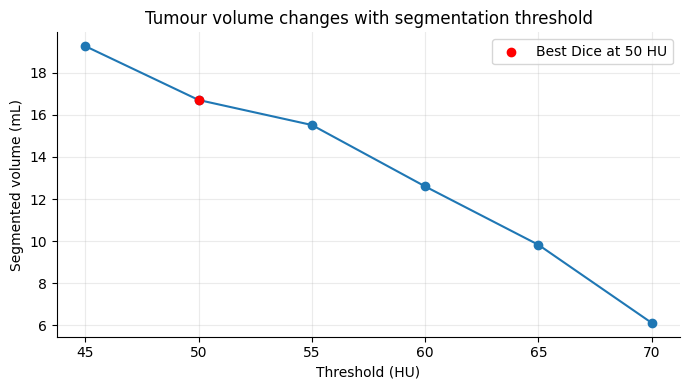

Across the tested thresholds, estimated volume ranges from 6.12 to 19.26 mL.
The best-Dice threshold in this evaluation is 50 HU (16.70 mL).


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2: threshold, take the connected component containing the detected centre,
# then calculate volume and (evaluation only) Dice overlap.
for threshold in [45, 50, 55, 60, 65, 70]:
    threshold_mask = vol > threshold
    components, _ = ndimage.label(threshold_mask)
    seed_component = components[cz, cy, cx]
    region = components == seed_component if seed_component != 0 else np.zeros_like(threshold_mask)
    voxel_count = int(region.sum())
    volume_ml = voxel_count * VOXEL_MM3 / 1000
    dice = (2 * np.logical_and(region, truth).sum() / (voxel_count + truth.sum())
            if voxel_count + truth.sum() else 0.0)
    rows.append({"Threshold (HU)": threshold, "Voxels": voxel_count,
                 "Volume (mL)": volume_ml, "Dice (evaluation only)": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3: plot volume vs threshold and mark the best-Dice threshold
best_row = table.loc[table["Dice (evaluation only)"].idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["Threshold (HU)"], table["Volume (mL)"], marker="o")
ax.scatter([best_row["Threshold (HU)"]], [best_row["Volume (mL)"]],
           color="red", zorder=3, label=f"Best Dice at {int(best_row['Threshold (HU)'])} HU")
ax.set_xlabel("Threshold (HU)"); ax.set_ylabel("Segmented volume (mL)")
ax.set_title("Tumour volume changes with segmentation threshold")
ax.grid(alpha=0.25); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4: report the full threshold-sensitivity range
volume_min = table["Volume (mL)"].min()
volume_max = table["Volume (mL)"].max()
print(f"Across the tested thresholds, estimated volume ranges from {volume_min:.2f} to {volume_max:.2f} mL.")
print(f"The best-Dice threshold in this evaluation is {int(best_row['Threshold (HU)'])} HU "
      f"({best_row['Volume (mL)']:.2f} mL).")

**Reflection:** Without ground truth, I would choose the threshold using the tumour's visible boundary on all three MPR planes, consistency with the radiologist's interpretation, and whether the resulting segmentation is anatomically plausible. I would document the selected threshold and have the radiologist review the overlay rather than choosing a value solely because it produces a preferred volume. I would show a threshold-sensitivity plot and report a volume interval alongside the selected estimate. This makes clear that the boundary is uncertain and that a small threshold change can materially change the measured volume.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

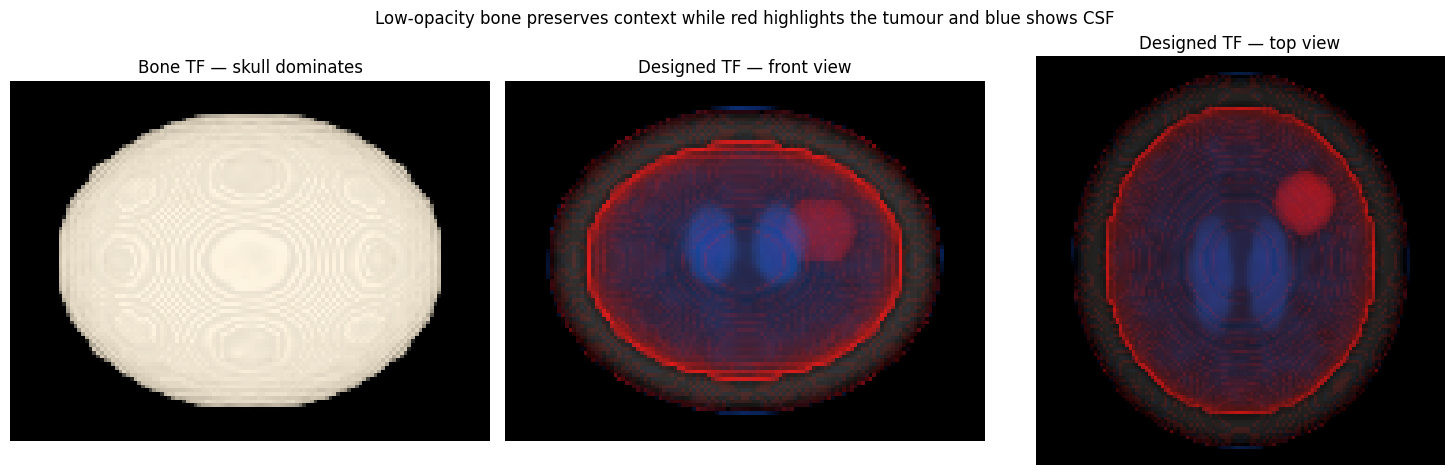

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: suppress air/soft tissue, keep bone nearly transparent, show CSF blue
# and tumour red. Low opacity limits accumulated occlusion along each ray.
tumour_tf = make_tf([
    (-1100, (0, 0, 0), 0.0),
    (-100, (0, 0, 0), 0.0),
    (4, (0, 0, 0), 0.0),
    (5, (0.10, 0.35, 1.0), 0.025),
    (20, (0.10, 0.45, 1.0), 0.035),
    (45, (0.0, 0.0, 0.0), 0.0),
    (55, (1.0, 0.05, 0.05), 0.075),
    (90, (1.0, 0.05, 0.05), 0.075),
    (110, (0.0, 0.0, 0.0), 0.0),
    (200, (0.0, 0.0, 0.0), 0.0),
    (300, (0.85, 0.8, 0.7), 0.003),
    (1000, (1.0, 1.0, 1.0), 0.005),
    (1500, (1.0, 1.0, 1.0), 0.005)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render, tumour TF front view, tumour TF top view
bone_color, bone_alpha = render(vol, bone_tf, axis=1)
front_color, front_alpha = render(vol, tumour_tf, axis=1)
top_color, top_alpha = render(vol, tumour_tf, axis=0)

axes[0].imshow(bone_color, origin="lower")
axes[0].set_title("Bone TF — skull dominates")
axes[1].imshow(front_color, origin="lower")
axes[1].set_title("Designed TF — front view")
axes[2].imshow(top_color, origin="lower")
axes[2].set_title("Designed TF — top view")
for ax in axes:
    ax.axis("off")

# TODO 4: conclusion-style title
fig.suptitle("Low-opacity bone preserves context while red highlights the tumour and blue shows CSF")
plt.tight_layout(); plt.show()

**Reflection:** The faint red rim is an example of **occlusion** from front-to-back volume compositing: opacity accumulates along each viewing ray, so even weak contributions from boundary voxels can become visible. A spatial technique such as **cropping/clipping** (or a spatially constrained segmentation mask) can remove the unwanted boundary region from the rendered volume. A transfer function alone maps intensity to colour and opacity; it cannot distinguish two voxels at different locations if they have the same HU value, so it cannot selectively remove the rim without also suppressing any tumour voxels with overlapping intensities.

## Task 5 — The Decision (No Code)

**Reflection (final):**

The detected lesion is in the upper, posterior part of the brain and slightly to the right of the volume's midline. Across the tested thresholds, its estimated volume ranges from **6.12 to 19.26 mL**, with the 50-HU segmentation giving the strongest evaluation overlap and an estimate of **16.70 mL**. I recommend opening the meeting with the **three-plane MPR**, because linked axial, coronal and sagittal slices expose internal anatomy without the occlusion that can hide structures in a 3-D volume render. The segmentation overlay and threshold-sensitivity plot should then be used to discuss the measured extent and its uncertainty. The 3-D render is useful for spatial context, but its appearance depends on the transfer function and accumulated opacity, so it should not be treated as an exact representation of tumour boundaries.